# Lecture 5: from a noisy pixel to a runnable DDPM

This notebook constructs a training tuple, inspects an actual model update, verifies a reverse step and samples from the local checkpoint. **Quick mode uses CPU, small batches and two samples; it keeps the full 1,000-step schedule.** Full training is an explicit optional cell. No network downloads occur.

Convention: one-based t=1,…,1000, ᾱ₀=1; β linearly increases from 0.0001 to 0.02. The denoiser predicts ε. Reverse variance is β̃ₜ and the final step adds no noise. Greyscale MNIST is transformed by uint8/127.5−1. The training loss averages over B×C×H×W.

In [1]:
from pathlib import Path
import sys, time, json, copy, os
ROOT=Path.cwd()
if not (ROOT/"scripts/ddpm.py").exists():
    ROOT=ROOT/"generative-series/lecture5"
sys.path.insert(0,str(ROOT/"scripts"))
import numpy as np
import torch
from torch.nn import functional as F
import matplotlib.pyplot as plt
from ddpm import TinyDenoiser, make_schedule, extract, reverse_step, sample_ddpm
get_ipython().run_line_magic("matplotlib", "inline")
torch.set_num_threads(2)
torch.manual_seed(667)
print("torch",torch.__version__,"device: cpu")
fixture=json.loads((ROOT/"data/fixtures.json").read_text())

torch 2.13.0 device: cpu


## 1. A schedule is more than a list of noise levels

**Predict:** what should ᾱ₀ be? Does a 20-step truncation of this schedule still end at almost pure noise? This implementation intentionally requires T=1000. A different step count requires designing and checking a different schedule.

In [2]:
def make_schedule(T=1000,device='cpu',dtype=torch.float32):
    if T!=1000: raise ValueError('This linear teaching schedule requires T=1000; define a new endpoint-checked schedule before changing T.')
    beta=torch.zeros(T+1,device=device,dtype=dtype)
    beta[1:]=torch.linspace(1e-4,2e-2,T,device=device,dtype=dtype)
    alpha=1-beta; ab=alpha.cumprod(0); var=torch.zeros_like(beta)
    var[1:]=beta[1:]*(1-ab[:-1])/(1-ab[1:])
    return beta,alpha,ab,var

alpha_bar at 20 and 1000: 0.9942309516861578 4.0358297653756754e-05


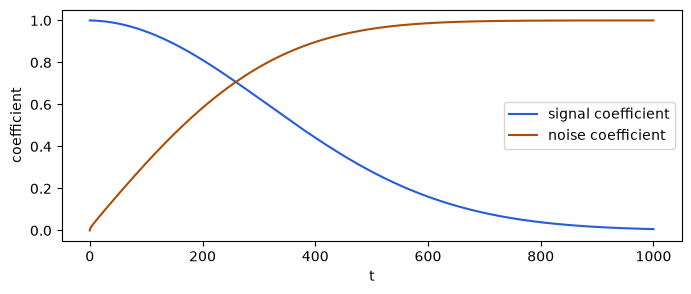

In [3]:
beta,alpha,alpha_bar,variance=make_schedule(dtype=torch.float64)
assert alpha_bar[0]==1 and variance[1]==0
assert alpha_bar[-1] < 5e-5
assert torch.allclose(alpha_bar[1:],torch.exp(torch.log(alpha[1:]).cumsum(0)),atol=1e-14)
print("alpha_bar at 20 and 1000:",float(alpha_bar[20]),float(alpha_bar[1000]))
fig,ax=plt.subplots(figsize=(8,3))
ax.plot(alpha_bar.sqrt(),label="signal coefficient",color="#245EDB")
ax.plot((1-alpha_bar).sqrt(),label="noise coefficient",color="#AA4E08")
ax.set(xlabel="t",ylabel="coefficient");ax.legend();plt.show()

## 2. One scalar example, one actual update

Chosen illustration: x₀=.8, t=350, ε=−.4. For this arithmetic only, let ε̂θ=θxₜ with θ=.3. The real image denoiser below is a U-Net. Keep these roles separate.

In [4]:
x0,t,eps=.8,350,-.4
xt=alpha_bar[t].sqrt()*x0+(1-alpha_bar[t]).sqrt()*eps
theta=torch.tensor(.3,dtype=torch.float64,requires_grad=True)
pred=theta*xt
loss=(pred-eps).square()
loss.backward()
grad=float(theta.grad)
eta=.1
with torch.no_grad():
    theta-=eta*theta.grad
    after=(theta*xt-eps).square()
print(dict(xt=float(xt),pred=float(pred.detach()),before=float(loss.detach()),
           gradient=grad,theta_after=float(theta),loss_after=float(after)))
assert abs(float(xt)-fixture["scalar"]["xt"])<1e-12
assert abs(float(after)-fixture["scalar"]["lossAfter"])<1e-12

{'xt': 0.08904908961952718, 'pred': 0.026714726885858152, 'before': 0.18208545814127253, 'gradient': 0.07599711591286169, 'theta_after': 0.2924002884087138, 'loss_after': 0.1815083599656067}


/var/folders/1x/wmgn24mn1bbd2vgbqlk98tbc0000gn/T/ipykernel_44835/2807654955.py:13: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /Users/runner/work/pytorch/pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:823.)
  gradient=grad,theta_after=float(theta),loss_after=float(after)))


In [5]:
def fixed_loss(value):
    return (value*float(xt)-eps)**2
h=1e-6
finite_diff=(fixed_loss(.3+h)-fixed_loss(.3-h))/(2*h)
print("autodiff / finite difference:",grad,finite_diff)
assert abs(grad-finite_diff)<1e-9

autodiff / finite difference: 0.07599711591286169 0.0759971159197681


## 3. Construct one image tuple

Use **official test index 0, digit7** for inspection. Earlier AE/VAE lectures used the held 3; this change is explicit. Test images are never used in the training-update cell. The bundled arrays preserve the first 512 training and first 128 test examples and labels.

held test label: 7


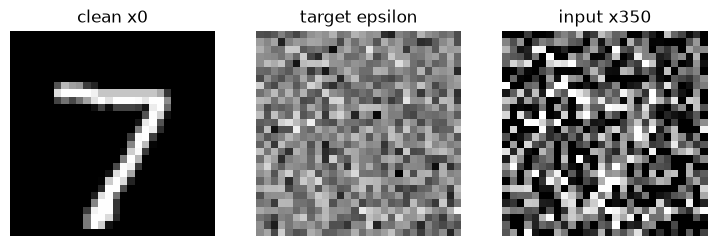

raw noisy range (not clipped): -3.1338696479797363 2.4996657371520996


In [6]:
data=np.load(ROOT/"data/mnist-subset.npz")
x0_image=torch.tensor(data["test"][0:1,None],dtype=torch.float32)/127.5-1
print("held test label:",int(data["test_labels"][0]))
schedule=make_schedule()
g=torch.Generator().manual_seed(667)
epsilon=torch.randn(x0_image.shape,generator=g)
timesteps=torch.tensor([350],dtype=torch.long)
a=extract(schedule[2],timesteps,x0_image)
noisy=a.sqrt()*x0_image+(1-a).sqrt()*epsilon
assert noisy.shape==epsilon.shape==(1,1,28,28)
fig,axes=plt.subplots(1,3,figsize=(9,3))
for ax,img,title,lim in zip(axes,[x0_image,epsilon,noisy],["clean x0","target epsilon","input x350"],[(-1,1),(-3,3),(-1,1)]):
    ax.imshow(img[0,0],cmap="gray",vmin=lim[0],vmax=lim[1]);ax.set_title(title);ax.axis("off")
plt.show()
print("raw noisy range (not clipped):",float(noisy.min()),float(noisy.max()))

The noisy input can be outside [−1,1]. Plotting chooses a display range; neither the training tensor nor the sampling state is clipped. Noise and image panels use explicitly different display ranges.

## 4. Load the checkpoint and inspect its prediction

The saved model was trained for 2,000 updates, batch 64, seed 667 on full greyscale MNIST training data. We replay it here; we do not claim a fresh full training run. Its denoiser has 814,145 parameters, time-conditioned residual blocks and U-Net skip connections.

parameters: 814145 saved updates: 2000


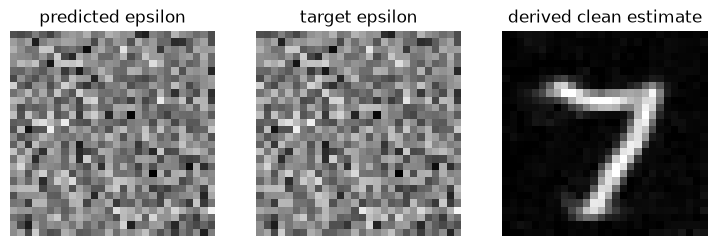

In [7]:
saved=torch.load(ROOT/"models/ddpm.pt",map_location="cpu",weights_only=True)
assert saved["contract"]=="linear1000-eps-posterior-v1"
model=TinyDenoiser();model.load_state_dict(saved["model"]);model.eval()
print("parameters:",sum(p.numel() for p in model.parameters()),"saved updates:",saved["steps"])
with torch.no_grad():
    predicted=model(noisy,timesteps)
    clean_estimate=(noisy-(1-a).sqrt()*predicted)/a.sqrt()
fig,axes=plt.subplots(1,3,figsize=(9,3))
for ax,img,title,lim in zip(axes,[predicted,epsilon,clean_estimate],["predicted epsilon","target epsilon","derived clean estimate"],[(-3,3),(-3,3),(-1,1)]):
    ax.imshow(img[0,0],cmap="gray",vmin=lim[0],vmax=lim[1]);ax.set_title(title);ax.axis("off")
plt.show()

Why need not predicted ε match the exact injected draw? Different clean images and noises can explain the same noisy input. At the population optimum, squared error learns a conditional mean. A clean estimate is also not the reverse mean or a newly sampled previous state.

## 5. One inspected neural update

Use **training indices 0–3**, not the held test 7. We hold t and ε fixed before/after solely to inspect the update. Ordinary training resamples them. The optimiser changes a copy of the checkpoint so the supplied file remains intact.

In [8]:
def inspect_training_update():
    local=TinyDenoiser();local.load_state_dict(saved["model"]);local.train()
    torch.manual_seed(2026)
    x0=torch.tensor(data["train"][:4,None],dtype=torch.float32)/127.5-1
    t=torch.tensor([7,100,350,920],dtype=torch.long)
    # Hold the same seed, images and timesteps as the displayed inspected update.
    eps=torch.randn_like(x0)
    a=extract(schedule[2],t,x0)
    xt=a.sqrt()*x0+(1-a).sqrt()*eps
    opt=torch.optim.SGD(local.parameters(),lr=.001)
    old=[p.detach().clone() for p in local.parameters()]
    opt.zero_grad(set_to_none=True)
    loss=F.mse_loss(local(xt,t),eps)
    loss.backward()
    grad_norm=float(sum(p.grad.square().sum() for p in local.parameters()).sqrt())
    opt.step()
    with torch.no_grad():after=float(F.mse_loss(local(xt,t),eps))
    delta=max(float((p-q).abs().max()) for p,q in zip(local.parameters(),old))
    assert grad_norm>0 and delta>0 and np.isfinite(after)
    return dict(before=float(loss.detach()),after_same_batch=after,gradient_norm=grad_norm,max_parameter_change=delta)
print(inspect_training_update())

{'before': 0.09844866394996643, 'after_same_batch': 0.09611958265304565, 'gradient_norm': 1.6255487203598022, 'max_parameter_change': 0.0001037372276186943}


## 6. Verify a reverse mean two different ways

Choose predicted ε=.25 for the scalar example. Compute the ε-parameterised mean and the posterior-mean expression using the derived x̂₀. Agreement checks the implementation; it does not make x̂₀ equal to the actual clean value.

In [9]:
t=350;current=float(xt);pred_eps=.25
clean=(current-np.sqrt(1-float(alpha_bar[t]))*pred_eps)/np.sqrt(float(alpha_bar[t]))
mean=(current-float(beta[t])*pred_eps/np.sqrt(1-float(alpha_bar[t])))/np.sqrt(float(alpha[t]))
c0=np.sqrt(float(alpha_bar[t-1]))*float(beta[t])/(1-float(alpha_bar[t]))
ct=np.sqrt(float(alpha[t]))*(1-float(alpha_bar[t-1]))/(1-float(alpha_bar[t]))
mean_independent=c0*clean+ct*current
assert abs(mean-mean_independent)<1e-12
xi=-.7
previous=mean+np.sqrt(float(variance[t]))*xi
print(dict(current=current,clean_estimate=clean,reverse_mean=mean,variance=float(variance[t]),previous_draw=previous))

{'current': 0.08904908961952718, 'clean_estimate': np.float64(-0.22903795345423936), 'reverse_mean': np.float64(0.08727208385462694), 'variance': 0.007032068694305391, 'previous_draw': np.float64(0.02857188231996744)}


### Final-step boundary

With posterior variance, β̃₁=0. Our sampler also explicitly omits the random term at t=1. The following test changes the proposed noise by an enormous amount and confirms the result is unchanged.

In [10]:
def reverse_step(x,eps,step,schedule,noise):
    b,a,ab,v=schedule
    mean=(x-b[step]*eps/(1-ab[step]).sqrt())/a[step].sqrt()
    return mean+v[step].sqrt()*noise if step>1 else mean

In [11]:
x=torch.tensor([.4]);pred=torch.tensor([.2])
a=reverse_step(x,pred,1,schedule,torch.tensor([999.]))
b=reverse_step(x,pred,1,schedule,torch.tensor([-999.]))
assert torch.equal(a,b)
print("final step independent of proposed random draw:",a)

final step independent of proposed random draw: tensor([0.3980])


## 7. Sample with the local model

CPU quick mode generates 2 images with all 1,000 reverse steps. The original checkpoint and the full 8-image replay used for slides remain separate. Record runtime; do not imply that every device has the same speed.

The complete executable sampling loop follows. These definitions are copied from the local companion source when this notebook is authored, so the visible algorithm and the executed implementation agree.

In [12]:
@torch.no_grad()
def sample_ddpm(model,shape,schedule,T=1000,device='cpu',seed=667,record=False):
    g=torch.Generator(device='cpu').manual_seed(seed)
    rand=lambda:torch.randn(shape,generator=g).to(device)
    x=rand();was=model.training;model.eval();frames={};estimates={}
    try:
        for step in range(T,0,-1):
            t=torch.full((shape[0],),step,device=device,dtype=torch.long);eps=model(x,t)
            if record and step in [1000,800,600,400,200,50,1]:
                frames[str(step)]=x.cpu().numpy();ab=schedule[2][step]
                estimates[str(step)]=((x-(1-ab).sqrt()*eps)/ab.sqrt()).cpu().numpy()
            x=reverse_step(x,eps,step,schedule,rand() if step>1 else torch.zeros_like(x))
        if record:frames['0']=x.cpu().numpy()
    finally:model.train(was)
    return (x,frames,estimates) if record else x

CPU sample seconds: 4.708520916057751 steps: 1000 samples: 2


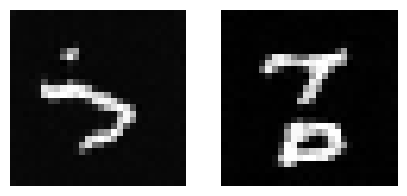

In [13]:
start=time.perf_counter()
samples=sample_ddpm(model,(2,1,28,28),schedule,seed=667)
seconds=time.perf_counter()-start
print("CPU sample seconds:",seconds,"steps:",1000,"samples:",2)
assert torch.isfinite(samples).all()
fig,axes=plt.subplots(1,2,figsize=(5,2.5))
for ax,img in zip(axes,samples):
    ax.imshow(img[0],cmap="gray",vmin=-1,vmax=1);ax.axis("off")
plt.show()

## 8. Optional fresh full training

Default is off. Set `MNIST_ROOT` to the local folder containing `train-images-idx3-ubyte.gz` and enable the cell. This trains a fresh model on the full training split and writes `models/full-training.pt`; it never overwrites the supplied checkpoint. No files are downloaded. The default 2000-update configuration matches the saved model’s intended training budget, not a guarantee of identical outputs across devices/versions.

In [14]:
RUN_FULL=False
if RUN_FULL:
    from train import train
    result=train(mode="full",steps=2000,device="cpu",
                 mnist_root=os.environ["MNIST_ROOT"],seed=667,batch_size=64)
    print(result)
else:
    print("Full fresh training is optional and was not executed in this notebook run.")

Full fresh training is optional and was not executed in this notebook run.


## Retrieval

1. What does the model receive? xₜ and t.
2. What is the known target during training? The sampled ε.
3. Is the clean estimate the reverse mean? No; they have different formulas and purposes.
4. What is added at t=1? No new random noise.
5. Is the simplified unweighted noise MSE the complete negative ELBO? No; timestep weights and boundary terms differ.

Sources: [Ho, Jain & Abbeel 2020](https://arxiv.org/abs/2006.11239); local model, schedule and sampling code adapted from Nipun Batra’s validated Generative Modelling II package. Checkpoint/data provenance is in `data/reuse-manifest.json` and `qa/science-checks.json`.